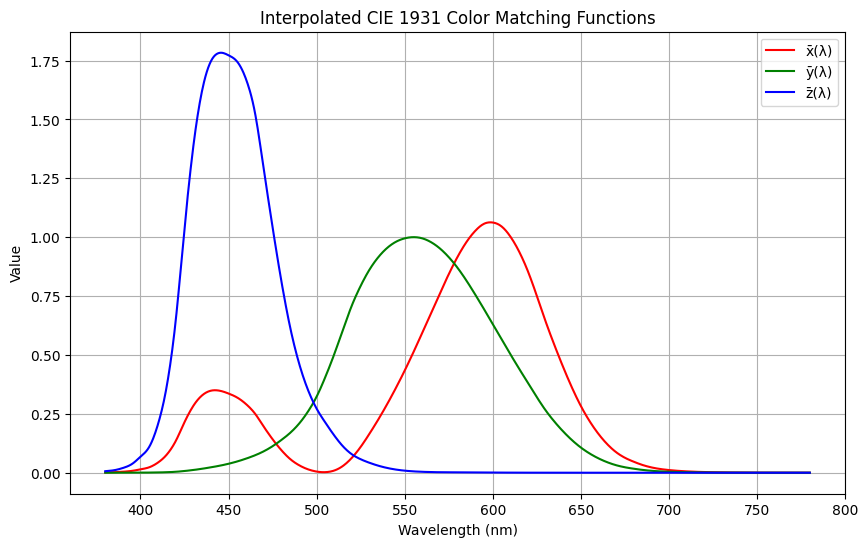

In [1]:
"""
This cell generates the CIE 1931 color-matching funtions,
i.e. mapping out the sensitivity to each wavelength each cone cell in your eye has.
"""
#import libraries
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import colour

#import CIE wavelength data (csv file)
cie_data = pd.read_csv('CIE_values.csv')

#retrieve values from csv file
wavelengths = cie_data['wavelength'].values
x_bar = cie_data['x_bar'].values
y_bar = cie_data['y_bar'].values
z_bar = cie_data['z_bar'].values

#interpolate data to create continuous line (instead of a ton of points)
common_wavelengths = np.linspace(380, 780, 1000)  # High-resolution grid
x_interp = interp1d(wavelengths, x_bar, kind='cubic', fill_value="extrapolate")
y_interp = interp1d(wavelengths, y_bar, kind='cubic', fill_value="extrapolate")
z_interp = interp1d(wavelengths, z_bar, kind='cubic', fill_value="extrapolate")

x_values = x_interp(common_wavelengths)
y_values = y_interp(common_wavelengths)
z_values = z_interp(common_wavelengths)

# Plot the interpolated functions
plt.figure(figsize=(10, 6))
plt.plot(common_wavelengths, x_values, label='x̄(λ)', color='red')
plt.plot(common_wavelengths, y_values, label='ȳ(λ)', color='green')
plt.plot(common_wavelengths, z_values, label='z̄(λ)', color='blue')
plt.title("Interpolated CIE 1931 Color Matching Functions")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Value")
plt.legend()
plt.grid()
plt.show()

Computed Tristimulus Values for water: 

X (.9c) = 100.0781
Y (.9c) = 100.0000
Z (.9c) = 187.3617


X (.8c) = 100.5608
Y (.8c) = 100.0000
Z (.8c) = 193.8698


X (.7c) = 141.7617
Y (.7c) = 100.0000
Z (.7c) = 749.3029


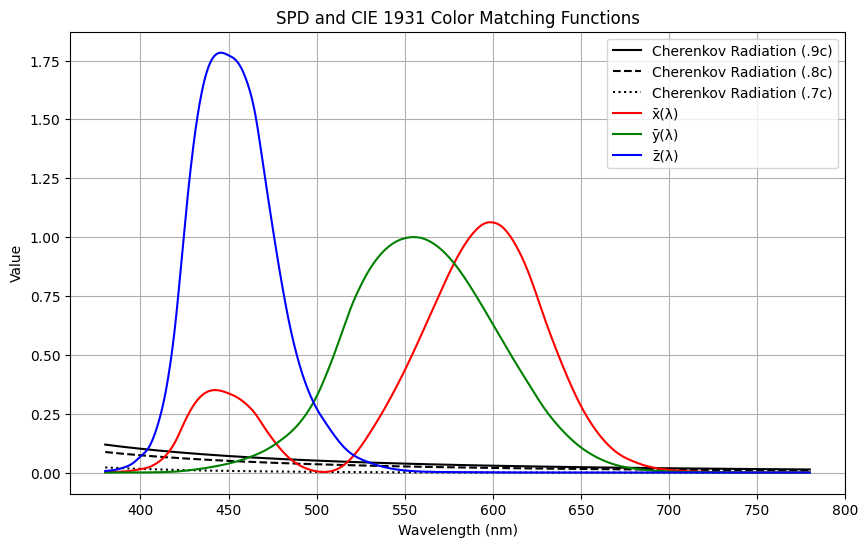

In [2]:
"""
This cell retrieves the data from Frank-Tamm calculations for water, 
plots data on top of CIE 1931 color-matching functions, 
and calculates corresponding XYZ values (by integration).
"""

#Retrieves data from water-based Frank-Tamm Formula
#https://docs.google.com/spreadsheets/d/1yxIFA6PXdJVl4J0zsTarDe7C8vWZlAqsqkvepjpXe80/edit?usp=sharing
sheet_id = '1yxIFA6PXdJVl4J0zsTarDe7C8vWZlAqsqkvepjpXe80'
cherenkov_data = pd.ExcelFile(f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?", engine='openpyxl')

water_energy = pd.read_excel(cherenkov_data, 'H2O-Energy Emission', header=0)
water_wavelengths = water_energy['wavelength (nm)'].values
water_values_9c = water_energy['Simulation Values (0.9c)'].values
water_values_8c = water_energy['Simulation Values (0.8c)'].values
water_values_7c = water_energy['Simulation Values (0.7c)'].values


# Interpolate retrieved Frank-Tamm data
energy_interp_water_9c = interp1d(water_wavelengths, water_values_9c, kind='cubic', fill_value="extrapolate")
energy_values_water_9c = energy_interp_water_9c(common_wavelengths)

energy_interp_water_8c = interp1d(water_wavelengths, water_values_8c, kind='cubic', fill_value="extrapolate")
energy_values_water_8c = energy_interp_water_8c(common_wavelengths)

energy_interp_water_7c = interp1d(water_wavelengths, water_values_7c, kind='cubic', fill_value="extrapolate")
energy_values_water_7c = energy_interp_water_7c(common_wavelengths)

# Compute normalization constant k
k_9c = 100 / np.trapezoid(energy_values_water_9c * y_values, common_wavelengths)
k_8c = 100 / np.trapezoid(energy_values_water_8c * y_values, common_wavelengths)
k_7c = 100 / np.trapezoid(energy_values_water_7c * y_values, common_wavelengths)

# Compute XYZ tristimulus values
X_water_9c = k_9c * np.trapezoid(energy_values_water_9c * x_values, common_wavelengths)
Y_water_9c = k_9c * np.trapezoid(energy_values_water_9c * y_values, common_wavelengths)
Z_water_9c = k_9c * np.trapezoid(energy_values_water_9c * z_values, common_wavelengths)

X_water_8c = k_8c * np.trapezoid(energy_values_water_8c * x_values, common_wavelengths)
Y_water_8c = k_8c * np.trapezoid(energy_values_water_8c * y_values, common_wavelengths)
Z_water_8c = k_8c * np.trapezoid(energy_values_water_8c * z_values, common_wavelengths)

X_water_7c = k_7c * np.trapezoid(energy_values_water_7c * x_values, common_wavelengths)
Y_water_7c = k_7c * np.trapezoid(energy_values_water_7c * y_values, common_wavelengths)
Z_water_7c = k_7c * np.trapezoid(energy_values_water_7c * z_values, common_wavelengths)

# Output the results
print(f"Computed Tristimulus Values for water: \n")

print(f"X (.9c) = {X_water_9c:.4f}")
print(f"Y (.9c) = {Y_water_9c:.4f}")
print(f"Z (.9c) = {Z_water_9c:.4f}")

print("\n")

print(f"X (.8c) = {X_water_8c:.4f}")
print(f"Y (.8c) = {Y_water_8c:.4f}")
print(f"Z (.8c) = {Z_water_8c:.4f}")

print("\n")

print(f"X (.7c) = {X_water_7c:.4f}")
print(f"Y (.7c) = {Y_water_7c:.4f}")
print(f"Z (.7c) = {Z_water_7c:.4f}")

# Visualize the SPD and matching functions
plt.figure(figsize=(10, 6))
plt.plot(common_wavelengths, energy_values_water_9c, label='Cherenkov Radiation (.9c)', color='black', linestyle='-')
plt.plot(common_wavelengths, energy_values_water_8c, label='Cherenkov Radiation (.8c)', color='black', linestyle='--')
plt.plot(common_wavelengths, energy_values_water_7c, label='Cherenkov Radiation (.7c)', color='black', linestyle=':')
plt.plot(common_wavelengths, x_values, label='x̄(λ)', color='red')
plt.plot(common_wavelengths, y_values, label='ȳ(λ)', color='green')
plt.plot(common_wavelengths, z_values, label='z̄(λ)', color='blue')
plt.title("SPD and CIE 1931 Color Matching Functions")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Value")
plt.legend()
plt.grid()
plt.show()

In [3]:
"""
This cell takes the computed tristimulus values from all mediums
 and converts them to plottable (x,y) coordinates via algebraic formula.
"""
def xyz_to_xy(X, Y, Z):
    total = X + Y + Z
    if total == 0:
        return 0, 0
    x = X / total
    y = Y / total
    return x, y

x_water_9c, y_water_9c = xyz_to_xy(X_water_9c, Y_water_9c, Z_water_9c)
x_water_8c, y_water_8c = xyz_to_xy(X_water_8c, Y_water_8c, Z_water_8c)
x_water_7c, y_water_7c = xyz_to_xy(X_water_7c, Y_water_7c, Z_water_7c)
print(f"Chromaticity Coordinates (.9c): x = {x_water_9c:.4f}, y = {y_water_9c:.4f} \n")
print(f"Chromaticity Coordinates (.8c): x = {x_water_8c:.4f}, y = {y_water_8c:.4f} \n")
print(f"Chromaticity Coordinates (.7c): x = {x_water_7c:.4f}, y = {y_water_7c:.4f} \n")

Chromaticity Coordinates (.9c): x = 0.2583, y = 0.2581 

Chromaticity Coordinates (.8c): x = 0.2550, y = 0.2535 

Chromaticity Coordinates (.7c): x = 0.1430, y = 0.1009 



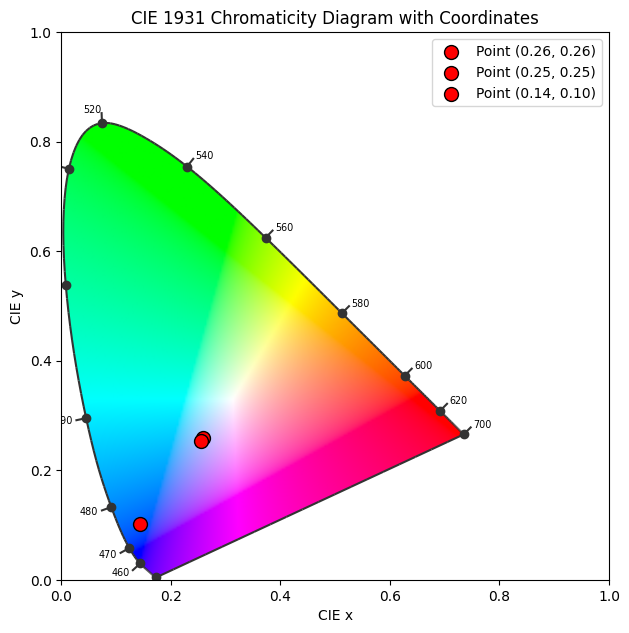

In [4]:
# Example (x, y) coordinates to plot
coordinates = [(x_water_9c, y_water_9c), (x_water_8c, y_water_8c), (x_water_7c, y_water_7c)]  # Replace with your points

# Plot the CIE 1931 Chromaticity Diagram
colour.plotting.plot_chromaticity_diagram_CIE1931(show=False)

# Overlay the points
for x, y in coordinates:
    plt.scatter(x, y, color='red', label=f"Point ({x:.2f}, {y:.2f})", s=100, edgecolors='black')
    
"""
x_center, y_center = 0.26, 0.26  # Center of zoom
zoom_range = 0.0001  # Define the range to zoom into
plt.xlim(x_center - zoom_range, x_center + zoom_range)
plt.ylim(y_center - zoom_range, y_center + zoom_range)
"""

# Add labels and legend
plt.legend()
plt.title("CIE 1931 Chromaticity Diagram with Coordinates")
plt.show()


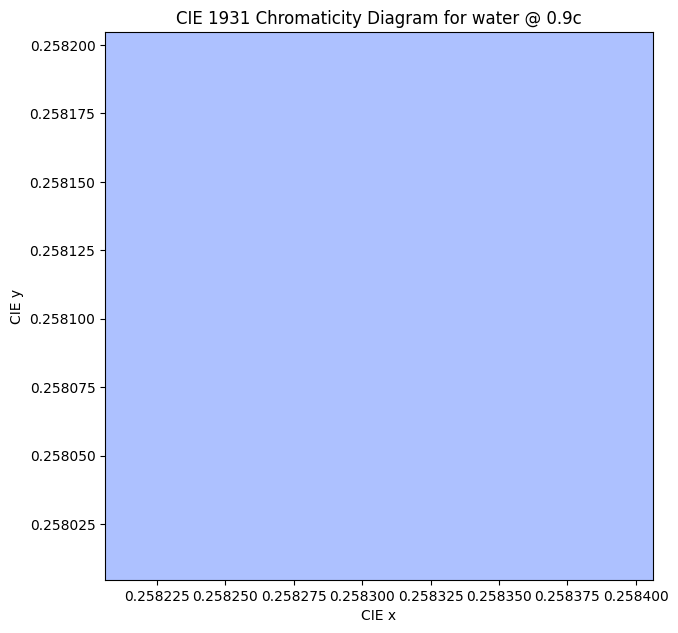

In [5]:
colour.plotting.plot_chromaticity_diagram_CIE1931(show=False)

x_center, y_center = x_water_9c, y_water_9c  # Center of zoom
zoom_range = 0.0001  # Define the range to zoom into
plt.xlim(x_center - zoom_range, x_center + zoom_range)
plt.ylim(y_center - zoom_range, y_center + zoom_range)

plt.title("CIE 1931 Chromaticity Diagram for water @ 0.9c")
plt.show()

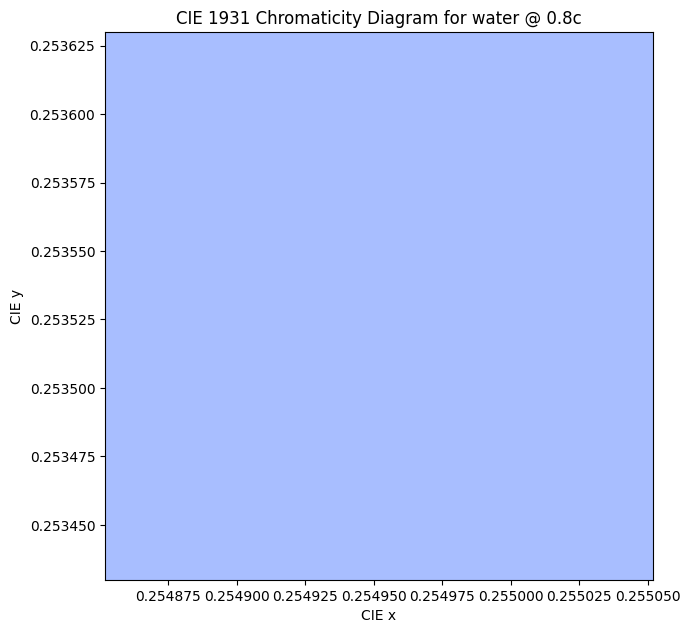

In [6]:
colour.plotting.plot_chromaticity_diagram_CIE1931(show=False)

x_center, y_center = x_water_8c, y_water_8c  # Center of zoom
zoom_range = 0.0001  # Define the range to zoom into
plt.xlim(x_center - zoom_range, x_center + zoom_range)
plt.ylim(y_center - zoom_range, y_center + zoom_range)

plt.title("CIE 1931 Chromaticity Diagram for water @ 0.8c")
plt.show()

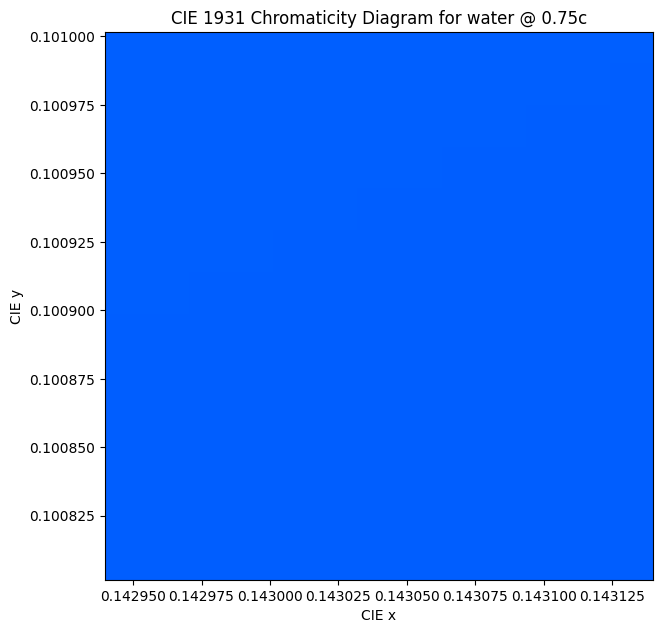

In [7]:
colour.plotting.plot_chromaticity_diagram_CIE1931(show=False)

x_center, y_center = x_water_7c, y_water_7c  # Center of zoom
zoom_range = 0.0001  # Define the range to zoom into
plt.xlim(x_center - zoom_range, x_center + zoom_range)
plt.ylim(y_center - zoom_range, y_center + zoom_range)

plt.title("CIE 1931 Chromaticity Diagram for water @ 0.75c")
plt.show()